# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Achmad Elrio
- **Email:** achmad.elrio@gmail.com
- **Username:** achmadelrio

## Menentukan Pertanyaan Bisnis
1. **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan total pendapatan (*revenue*) tertinggi dan volume pesanan (*order volume*) tertinggi pada transaksi berstatus *delivered* selama periode Januari 2017 hingga Agustus 2018, serta bagaimana tren pendapatan bulanannya, sebagai dasar penentuan prioritas kategori promosi dan pengelolaan stok?
2. **Pertanyaan 2:** Bagaimana perbandingan rata-rata skor ulasan pelanggan (*review score*) antara pesanan berstatus *delivered* yang tiba tepat waktu (*on-time*) dan yang terlambat (*late*) dari tanggal estimasi pengiriman selama periode Januari 2017 hingga Agustus 2018, sebagai dasar evaluasi ketepatan waktu pengiriman?

## Import Semua Packages/Library yang Digunakan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling
### Gathering Data
Memuat seluruh tabel dataset dari direktori `data/` ke dalam DataFrame.

In [3]:
orders_df = pd.read_csv("data/orders_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")
order_reviews_df = pd.read_csv("data/order_reviews_dataset.csv")
products_df = pd.read_csv("data/products_dataset.csv")
category_trans_df = pd.read_csv("data/product_category_name_translation.csv")
customers_df = pd.read_csv("data/customers_dataset.csv")

print("orders_df:", orders_df.shape)
print("order_items_df:", order_items_df.shape)
print("order_reviews_df:", order_reviews_df.shape)
print("products_df:", products_df.shape)
print("category_trans_df:", category_trans_df.shape)
print("customers_df:", customers_df.shape)

orders_df: (99441, 8)
order_items_df: (112650, 7)
order_reviews_df: (99224, 7)
products_df: (32951, 9)
category_trans_df: (71, 2)
customers_df: (99441, 5)


**Insight Gathering Data:**
- Seluruh 6 tabel berhasil dimuat ke dalam DataFrame: `orders_df` (99.441 baris), `order_items_df` (112.650 baris), `order_reviews_df` (99.224 baris), `products_df` (32.951 baris), `category_trans_df` (71 baris), dan `customers_df` (99.441 baris).

### Assessing Data
Memeriksa tipe data, *missing value*, sebaran nilai kosong berdasarkan status pesanan, dan duplikasi data.

In [4]:
print("=== 1. ASSESSING ORDERS_DF ===")
orders_df.info()
print("\nJumlah missing value pada orders_df:\n", orders_df.isna().sum()[orders_df.isna().sum() > 0])
print("\nSebaran missing value berdasarkan order_status:")
print(orders_df.groupby("order_status")[["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]].apply(lambda g: g.isna().sum()))
print("\nJumlah duplikasi baris penuh orders_df:", orders_df.duplicated().sum())

=== 1. ASSESSING ORDERS_DF ===
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

Jumlah missing value pada orders_df:
 order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Sebaran missing value berdasarkan order_status:
              order_approved_at  order_d

In [5]:
print("=== 2. ASSESSING ORDER_ITEMS_DF ===")
print(order_items_df.describe())
print("Jumlah missing value order_items_df:", order_items_df.isna().sum().sum())
print("Jumlah duplikasi baris penuh order_items_df:", order_items_df.duplicated().sum())

print("\n=== 3. ASSESSING ORDER_REVIEWS_DF ===")
print("Jumlah duplikasi baris penuh order_reviews_df:", order_reviews_df.duplicated().sum())
print("Jumlah duplikasi order_id pada order_reviews_df:", order_reviews_df["order_id"].duplicated().sum())

print("\n=== 4. ASSESSING PRODUCTS_DF ===")
print("Jumlah missing value pada products_df:\n", products_df.isna().sum()[products_df.isna().sum() > 0])
print("Jumlah duplikasi baris penuh products_df:", products_df.duplicated().sum())

=== 2. ASSESSING ORDER_ITEMS_DF ===
       order_item_id          price  freight_value
count  112650.000000  112650.000000  112650.000000
mean        1.197834     120.653739      19.990320
std         0.705124     183.633928      15.806405
min         1.000000       0.850000       0.000000
25%         1.000000      39.900000      13.080000
50%         1.000000      74.990000      16.260000
75%         1.000000     134.900000      21.150000
max        21.000000    6735.000000     409.680000
Jumlah missing value order_items_df: 0
Jumlah duplikasi baris penuh order_items_df: 0

=== 3. ASSESSING ORDER_REVIEWS_DF ===
Jumlah duplikasi baris penuh order_reviews_df: 0
Jumlah duplikasi order_id pada order_reviews_df: 551

=== 4. ASSESSING PRODUCTS_DF ===
Jumlah missing value pada products_df:
 product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2


**Insight Assessing Data & Rencana Solusi:**
1. **Tipe Data Tidak Sesuai (`orders_df`):** Berdasarkan output `orders_df.info()`, kelima kolom tanggal (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, dan `order_estimated_delivery_date`) masih bertipe string (`str`), bukan `datetime`.
   - **Solusi:** Mengonversi kelima kolom tanggal tersebut ke tipe `datetime` menggunakan `pd.to_datetime()`.
2. **Missing Value (`orders_df`):** Ditemukan nilai kosong pada `order_approved_at` (160), `order_delivered_carrier_date` (1.783), dan `order_delivered_customer_date` (2.965). Tabel sebaran per `order_status` menunjukkan bahwa sebagian besar nilai kosong pada `order_delivered_customer_date` berasal dari pesanan berstatus selain `delivered` (`shipped` 1.107, `canceled` 619, `unavailable` 609, `invoiced` 314, `processing` 301, `created` 5, dan `approved` 2), serta 8 baris pada status `delivered`.
   - **Solusi:** Memfilter data agar hanya mencakup status `delivered` dan memiliki tanggal tiba pelanggan yang tidak kosong (`notna()`).
3. **Duplikasi Data (`order_reviews_df`):** Ditemukan **551 duplikasi `order_id`** karena satu pesanan dapat memiliki lebih dari satu baris ulasan.
   - **Solusi:** Menghapus duplikasi berdasarkan `order_id` dengan mempertahankan ulasan terbaru (`drop_duplicates(subset=["order_id"], keep="last")`).
4. **Missing Value (`products_df`):** Terdapat **610 *missing value*** pada kolom `product_category_name`.
   - **Solusi:** Menggabungkan tabel produk dengan `category_trans_df` lalu mengisi kategori yang kosong dengan label `'unknown'`.

### Cleaning Data
Menerapkan solusi pembersihan data sesuai temuan pada tahap *Assessing Data* dan memeriksa ulang hasilnya.

In [6]:
# 1. Konversi kolom tanggal pada orders_df menjadi datetime
datetime_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in datetime_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Filter pesanan berstatus 'delivered' dan tanggal tiba pelanggan tidak kosong
orders_clean = orders_df[
    (orders_df["order_status"] == "delivered") &
    (orders_df["order_delivered_customer_date"].notna())
].copy()

# 3. Hapus duplikasi order_id pada order_reviews_df
reviews_clean = order_reviews_df.sort_values("review_creation_date").drop_duplicates(subset=["order_id"], keep="last").copy()

# 4. Gabungkan produk dengan terjemahan kategori & isi missing value dengan 'unknown'
products_clean = products_df.merge(category_trans_df, on="product_category_name", how="left")
products_clean["product_category_name_english"] = products_clean["product_category_name_english"].fillna("unknown")

# Verifikasi ulang hasil cleaning
orders_clean.info()
print("\nMissing value orders_clean:\n", orders_clean.isna().sum())
print("\nJumlah duplikasi order_id reviews_clean:", reviews_clean["order_id"].duplicated().sum())
print("Missing value kategori produk products_clean:", products_clean["product_category_name_english"].isna().sum())

<class 'pandas.DataFrame'>
Index: 96470 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96470 non-null  str           
 1   customer_id                    96470 non-null  str           
 2   order_status                   96470 non-null  str           
 3   order_purchase_timestamp       96470 non-null  datetime64[us]
 4   order_approved_at              96456 non-null  datetime64[us]
 5   order_delivered_carrier_date   96469 non-null  datetime64[us]
 6   order_delivered_customer_date  96470 non-null  datetime64[us]
 7   order_estimated_delivery_date  96470 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 13.4 MB

Missing value orders_clean:
 order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_ap

**Insight Cleaning Data:**
- Verifikasi ulang memastikan kelima kolom tanggal pada `orders_clean` telah bertipe `datetime64`, tidak ada lagi nilai kosong pada seluruh kolom (`96.470` baris valid), jumlah duplikasi `order_id` pada `reviews_clean` menjadi `0`, dan seluruh produk telah memiliki label kategori bahasa Inggris (termasuk `'unknown'` untuk kategori yang sebelumnya kosong).

## Exploratory Data Analysis (EDA)
Menggabungkan tabel bersih menjadi DataFrame terpadu `main_data`, memfilter periode **Januari 2017 hingga Agustus 2018**, dan menghitung agregasi untuk menjawab Pertanyaan 1 dan Pertanyaan 2.

In [7]:
# Menggabungkan seluruh tabel bersih
main_data = (
    orders_clean[["order_id", "customer_id", "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]]
    .merge(customers_df[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
    .merge(order_items_df[["order_id", "order_item_id", "product_id", "price", "freight_value"]], on="order_id", how="inner")
    .merge(products_clean[["product_id", "product_category_name_english"]], on="product_id", how="left")
    .merge(reviews_clean[["order_id", "review_score"]], on="order_id", how="left")
)

main_data["delay_days"] = (main_data["order_delivered_customer_date"] - main_data["order_estimated_delivery_date"]).dt.days
main_data["delivery_status"] = np.where(main_data["delay_days"] > 0, "Late (Terlambat)", "On-Time (Tepat Waktu)")

# Filter periode analisis: Januari 2017 - Agustus 2018
sales_period = main_data[
    (main_data["order_purchase_timestamp"] >= "2017-01-01") &
    (main_data["order_purchase_timestamp"] <= "2018-08-31")
].copy()

# --- EDA Pertanyaan 1: Performa Seluruh Kategori & Tren Bulanan ---
cat_summary = sales_period.groupby("product_category_name_english").agg(
    total_revenue=("price", "sum"),
    total_orders=("order_id", "nunique")
).reset_index()

top10_revenue = cat_summary.sort_values(by="total_revenue", ascending=False).head(10)
top10_orders = cat_summary.sort_values(by="total_orders", ascending=False).head(10)

print("=== TOP 10 KATEGORI BY TOTAL REVENUE (SELURUH KATEGORI) ===")
print(top10_revenue)
print("\n=== TOP 10 KATEGORI BY VOLUME PESANAN (SELURUH KATEGORI) ===")
print(top10_orders)

sales_period["year_month"] = sales_period["order_purchase_timestamp"].dt.to_period("M").astype(str)
monthly_trend = sales_period.groupby("year_month").agg(
    revenue=("price", "sum"),
    orders=("order_id", "nunique")
).reset_index()

print("\n=== TREN PENDAPATAN & JUMLAH PESANAN BULANAN (JAN 2017 - AGU 2018) ===")
print(monthly_trend)

# --- EDA Pertanyaan 2: Perbandingan Review Score berdasarkan Status Pengiriman ---
q2_orders = sales_period.dropna(subset=["review_score"]).drop_duplicates(subset=["order_id"]).copy()
review_summary = q2_orders.groupby("delivery_status").agg(
    jumlah_pesanan=("order_id", "count"),
    rata_rata_skor=("review_score", "mean"),
    median_skor=("review_score", "median")
).reset_index()

print("\n=== PERBANDINGAN REVIEW SCORE BERDASARKAN STATUS PENGIRIMAN ===")
print(review_summary)
print("Total pesanan berulasan pada periode analisis:", review_summary["jumlah_pesanan"].sum())

=== TOP 10 KATEGORI BY TOTAL REVENUE (SELURUH KATEGORI) ===
   product_category_name_english  total_revenue  total_orders
43                 health_beauty     1229557.50          8610
71                 watches_gifts     1163187.91          5489
7                 bed_bath_table     1022955.77          9267
65                sports_leisure      952661.40          7512
15         computers_accessories      887944.60          6517
39               furniture_decor      706237.17          6258
49                    housewares      614341.62          5734
20                    cool_stuff      609158.00          3552
5                           auto      577721.09          3801
42                  garden_tools      469135.40          3443

=== TOP 10 KATEGORI BY VOLUME PESANAN (SELURUH KATEGORI) ===
   product_category_name_english  total_revenue  total_orders
7                 bed_bath_table     1022955.77          9267
43                 health_beauty     1229557.50          8610
65        

**Insight Exploratory Data Analysis (EDA):**
1. **Pertanyaan 1 (Performa Kategori & Tren Bulanan):**
   - Dari seluruh kategori produk pada transaksi *delivered* periode Januari 2017–Agustus 2018, kategori **`health_beauty`** menghasilkan total pendapatan tertinggi sebesar **1.229.557,50 BRL** (8.610 pesanan), diikuti **`watches_gifts`** (**1.163.187,91 BRL**) dan **`bed_bath_table`** (**1.022.955,77 BRL**).
   - Berdasarkan volume pesanan di seluruh kategori, **`bed_bath_table`** menempati posisi tertinggi dengan **9.267 pesanan**, diikuti **`health_beauty`** (**8.610 pesanan**) dan **`sports_leisure`** (**7.512 pesanan**).
   - Tren pendapatan bulanan tumbuh dari **111.798,36 BRL** (Januari 2017) hingga mencapai puncak tertinggi pada **November 2017** sebesar **987.648,07 BRL** (7.288 pesanan), dengan penurunan sementara pada **April 2017** (dari 359.198,85 BRL menjadi 340.669,68 BRL) dan **Juni 2017** (dari 489.159,25 BRL menjadi 421.923,37 BRL). Setelah turun menjadi 726.033,19 BRL pada Desember 2017, pendapatan bulanan bergerak stabil di kisaran **826.437,13 BRL hingga 977.544,69 BRL** sepanjang Januari–Agustus 2018.
2. **Pertanyaan 2 (Ketepatan Pengiriman vs Skor Ulasan):**
   - Dari total **95.560 pesanan** *delivered* yang memiliki ulasan pada periode Januari 2017–Agustus 2018, **89.182 pesanan (93,33%)** tiba tepat waktu (*On-Time*) dengan rata-rata skor ulasan **4,29** (median **5,0**).
   - Sebaliknya, **6.378 pesanan (6,67%)** yang tiba terlambat (*Late*) mencatat rata-rata skor ulasan **2,27** (median **1,0**), atau lebih rendah **2,02 poin** dibandingkan pesanan tepat waktu.

## Visualization & Explanatory Analysis
#### Pertanyaan 1: Kategori produk apa saja yang menghasilkan total pendapatan (revenue) tertinggi dan volume pesanan (order volume) tertinggi pada transaksi berstatus delivered selama periode Januari 2017 hingga Agustus 2018, serta bagaimana tren pendapatan bulanannya, sebagai dasar penentuan prioritas kategori promosi dan pengelolaan stok?

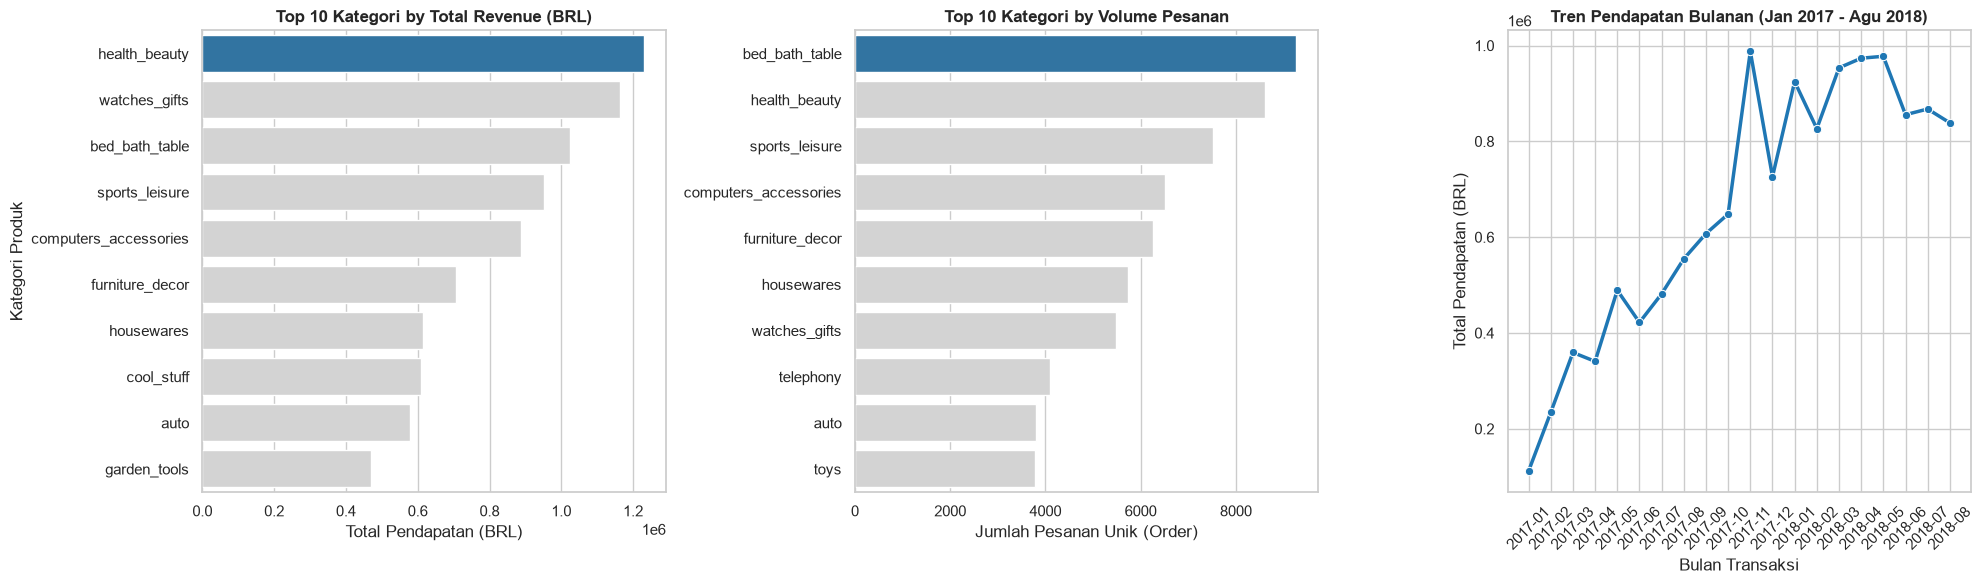

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

colors_rev = ["#1f77b4" if i == 0 else "#D3D3D3" for i in range(len(top10_revenue))]
sns.barplot(
    data=top10_revenue, x="total_revenue", y="product_category_name_english",
    hue="product_category_name_english", palette=colors_rev, legend=False, ax=axes[0]
)
axes[0].set_title("Top 10 Kategori by Total Revenue (BRL)", fontweight="bold")
axes[0].set_xlabel("Total Pendapatan (BRL)")
axes[0].set_ylabel("Kategori Produk")

colors_ord = ["#1f77b4" if i == 0 else "#D3D3D3" for i in range(len(top10_orders))]
sns.barplot(
    data=top10_orders, x="total_orders", y="product_category_name_english",
    hue="product_category_name_english", palette=colors_ord, legend=False, ax=axes[1]
)
axes[1].set_title("Top 10 Kategori by Volume Pesanan", fontweight="bold")
axes[1].set_xlabel("Jumlah Pesanan Unik (Order)")
axes[1].set_ylabel("")

sns.lineplot(data=monthly_trend, x="year_month", y="revenue", marker="o", linewidth=2.5, color="#1f77b4", ax=axes[2])
axes[2].set_title("Tren Pendapatan Bulanan (Jan 2017 - Agu 2018)", fontweight="bold")
axes[2].set_xlabel("Bulan Transaksi")
axes[2].set_ylabel("Total Pendapatan (BRL)")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

#### Pertanyaan 2: Bagaimana perbandingan rata-rata skor ulasan pelanggan (review score) antara pesanan berstatus delivered yang tiba tepat waktu (on-time) dan yang terlambat (late) dari tanggal estimasi pengiriman selama periode Januari 2017 hingga Agustus 2018, sebagai dasar evaluasi ketepatan waktu pengiriman?

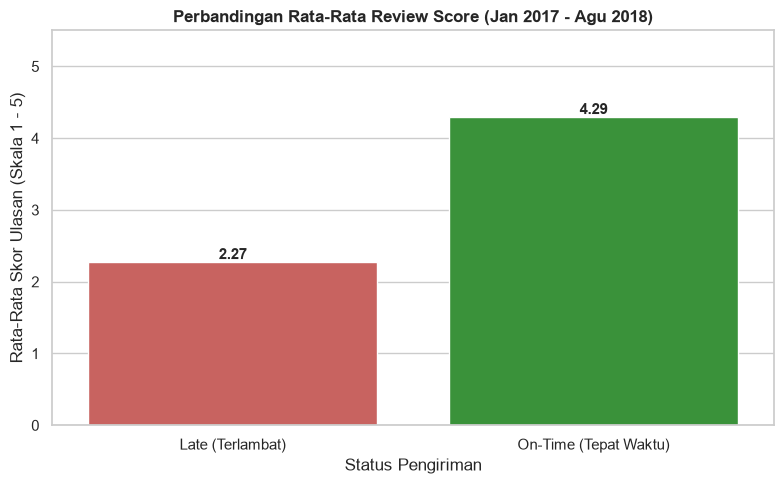

In [9]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=review_summary, x="delivery_status", y="rata_rata_skor",
    hue="delivery_status", palette=["#d9534f", "#2ca02c"], legend=False
)
plt.title("Perbandingan Rata-Rata Review Score (Jan 2017 - Agu 2018)", fontweight="bold")
plt.xlabel("Status Pengiriman")
plt.ylabel("Rata-Rata Skor Ulasan (Skala 1 - 5)")
plt.ylim(0, 5.5)

for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.2f}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center", va="bottom", fontsize=11, fontweight="bold"
    )

plt.tight_layout()
plt.show()

**Insight Visualization & Explanatory Analysis:**
- **Visualisasi Pertanyaan 1** memperlihatkan bahwa `health_beauty` merupakan kategori dengan pendapatan terbesar (1,23 juta BRL), sementara `bed_bath_table` unggul pada jumlah pesanan (9.267 pesanan), dengan puncak pendapatan bulanan terjadi pada November 2017 (987,65 ribu BRL).
- **Visualisasi Pertanyaan 2** memperlihatkan selisih skor ulasan yang nyata antara pengiriman tepat waktu (**4,29**) dan pengiriman terlambat (**2,27**).

## Analisis Lanjutan: RFM Analysis & Customer Segmentation
**Tujuan Analisis:** Mengukur perilaku pembelian pelanggan unik (`customer_unique_id`) pada transaksi *delivered* periode Januari 2017–Agustus 2018 berdasarkan metrik **Recency**, **Frequency**, dan **Monetary**, serta mengelompokkan pelanggan (*Manual Grouping / Clustering* tanpa algoritma *machine learning*) menjadi 4 segmen untuk menentukan strategi retensi pelanggan.

Snapshot Date: 2018-08-30 15:00:37

=== RINGKASAN STATISTIK METRIK RFM ===
        recency  frequency  monetary
count  93096.00   93096.00  93096.00
mean     236.71       1.03    141.57
std      150.94       0.21    215.77
min        1.00       1.00      0.85
25%      114.00       1.00     47.65
50%      218.00       1.00     89.70
75%      345.00       1.00    154.16
max      602.00      15.00  13440.00

=== DISTRIBUSI SEGMEN PELANGGAN ===
           customer_segment  customer_count  percentage
0  Inactive One-Time Buyers           72467       77.84
1    Recent One-Time Buyers           17840       19.16
2  At-Risk Repeat Customers            1558        1.67
3    Loyal Active Customers            1231        1.32


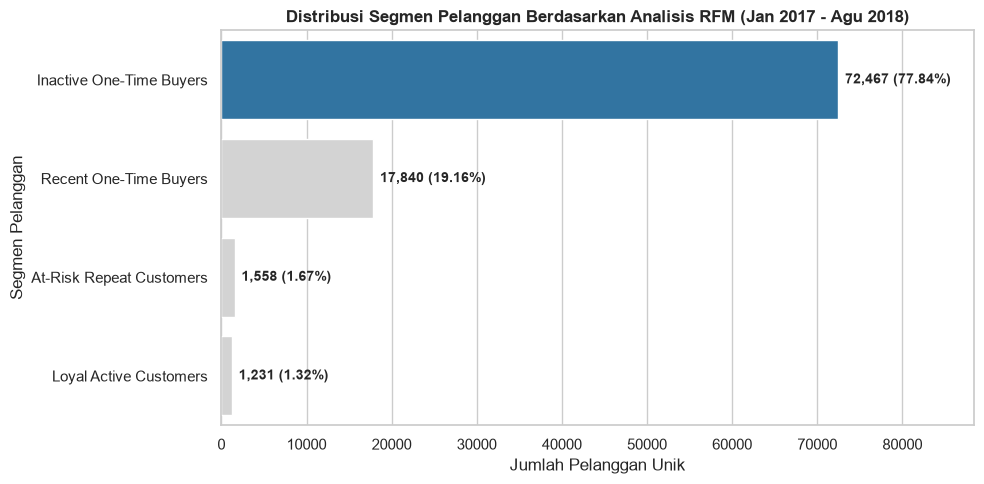

In [10]:
snapshot_date = sales_period["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
print("Snapshot Date:", snapshot_date)

rfm_df = sales_period.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp", lambda x: (snapshot_date - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
).reset_index()

print("\n=== RINGKASAN STATISTIK METRIK RFM ===")
print(rfm_df[["recency", "frequency", "monetary"]].describe().round(2))

def classify_customer(row):
    if row["frequency"] > 1 and row["recency"] <= 180:
        return "Loyal Active Customers"
    elif row["frequency"] > 1 and row["recency"] > 180:
        return "At-Risk Repeat Customers"
    elif row["frequency"] == 1 and row["recency"] <= 90:
        return "Recent One-Time Buyers"
    else:
        return "Inactive One-Time Buyers"

rfm_df["customer_segment"] = rfm_df.apply(classify_customer, axis=1)

segment_summary = rfm_df["customer_segment"].value_counts().reset_index()
segment_summary.columns = ["customer_segment", "customer_count"]
segment_summary["percentage"] = (segment_summary["customer_count"] / len(rfm_df) * 100).round(2)

print("\n=== DISTRIBUSI SEGMEN PELANGGAN ===")
print(segment_summary)

plt.figure(figsize=(10, 5))
colors_seg = ["#1f77b4" if i == 0 else "#D3D3D3" for i in range(len(segment_summary))]
ax_seg = sns.barplot(
    data=segment_summary, x="customer_count", y="customer_segment",
    hue="customer_segment", palette=colors_seg, legend=False
)
plt.title("Distribusi Segmen Pelanggan Berdasarkan Analisis RFM (Jan 2017 - Agu 2018)", fontweight="bold")
plt.xlabel("Jumlah Pelanggan Unik")
plt.ylabel("Segmen Pelanggan")

for p in ax_seg.patches:
    width = p.get_width()
    ax_seg.annotate(
        f"{int(width):,} ({width/len(rfm_df)*100:.2f}%)",
        (width + 800, p.get_y() + p.get_height() / 2.),
        va="center", fontsize=10, fontweight="bold"
    )
plt.xlim(0, segment_summary["customer_count"].max() * 1.22)
plt.tight_layout()
plt.show()

**Insight Analisis Lanjutan (RFM & Segmentasi Pelanggan):**
- Dengan tanggal acuan (`snapshot_date`) **`2018-08-30 15:00:37`**, analisis terhadap **93.096 pelanggan unik** menunjukkan rata-rata *recency* **236,71 hari**, rata-rata *frequency* **1,03 transaksi** (maksimum 15 transaksi), dan rata-rata *monetary* **141,57 BRL** (maksimum 13.440,00 BRL).
- Hasil pengelompokan (*Manual Grouping*) membagi pelanggan ke dalam 4 segmen:
  1. **Inactive One-Time Buyers** (*frequency = 1*, *recency > 90 hari*): **72.467 pelanggan (77,84%)**.
  2. **Recent One-Time Buyers** (*frequency = 1*, *recency <= 90 hari*): **17.840 pelanggan (19,16%)**.
  3. **At-Risk Repeat Customers** (*frequency > 1*, *recency > 180 hari*): **1.558 pelanggan (1,67%)**.
  4. **Loyal Active Customers** (*frequency > 1*, *recency <= 180 hari*): **1.231 pelanggan (1,32%)**.

In [11]:
cols_dashboard = [
    "order_id",
    "customer_unique_id",
    "order_purchase_timestamp",
    "product_category_name_english",
    "price",
    "review_score",
    "delivery_status"
]
main_data[cols_dashboard].to_csv("dashboard/main_data.csv", index=False)
print("Berhasil menyimpan dashboard/main_data.csv:", main_data[cols_dashboard].shape)

Berhasil menyimpan dashboard/main_data.csv: (110189, 7)


## Conclusion
1. **Kesimpulan Pertanyaan 1:** Selama periode Januari 2017 hingga Agustus 2018 pada transaksi berstatus *delivered*, kategori **`health_beauty`** menghasilkan total pendapatan tertinggi sebesar **1.229.557,50 BRL**, sedangkan kategori **`bed_bath_table`** menghasilkan volume pesanan tertinggi di seluruh kategori sebanyak **9.267 pesanan**. Tren pendapatan bulanan tumbuh dari 111.798,36 BRL (Januari 2017) hingga mencapai puncak tertinggi pada **November 2017** sebesar **987.648,07 BRL** (7.288 pesanan), lalu bergerak stabil di kisaran 826 ribu–977 ribu BRL per bulan sepanjang Januari–Agustus 2018.
2. **Kesimpulan Pertanyaan 2:** Dari 95.560 pesanan *delivered* yang memiliki ulasan pada periode Januari 2017 hingga Agustus 2018, pesanan yang tiba tepat waktu (*On-Time*, 89.182 pesanan) memperoleh rata-rata skor ulasan sebesar **4,29**, sedangkan pesanan yang terlambat (*Late*, 6.378 pesanan) memiliki rata-rata skor ulasan jauh lebih rendah yaitu **2,27** (selisih **2,02 poin**).
3. **Kesimpulan Analisis Lanjutan (RFM):** Sebagian besar basis pelanggan didominasi oleh pembeli satu kali yang tidak aktif (**Inactive One-Time Buyers** sebesar **77,84%**), sementara segmen pelanggan berulang yang masih aktif (**Loyal Active Customers**) baru mencapai **1,32%** (1.231 pelanggan).

## Recommendation (Action Items)
1. **Prioritas Kategori Promosi dan Ketersediaan Stok:** Tim *Marketing* dan *Merchandising* disarankan memprioritaskan kategori **`health_beauty`**, **`watches_gifts`**, dan **`bed_bath_table`** sebagai produk utama dalam kampanye promosi serta menjaga ketersediaan stoknya secara optimal untuk memaksimalkan kontribusi pendapatan dan volume transaksi.
2. **Audit dan Evaluasi Kinerja Ketepatan Pengiriman:** Tim *Operations* disarankan mengevaluasi proses pemenuhan pesanan (*fulfillment*) dan mitra pengiriman pada **6.378 pesanan** yang mengalami keterlambatan (*Late*), karena keterlambatan berkaitan langsung dengan turunnya rata-rata skor ulasan pelanggan hingga angka **2,27**.
3. **Kampanye Retensi untuk Segmen *Recent One-Time Buyers* dan *At-Risk Repeat Customers*:** Tim *CRM* disarankan menargetkan **17.840 pelanggan** pada segmen *Recent One-Time Buyers* dengan penawaran pembelian kedua sebelum mereka berpindah ke segmen *Inactive*, serta mengirimkan kampanye reaktivasi khusus kepada **1.558 pelanggan** di segmen *At-Risk Repeat Customers*.